In [49]:
from sklearn.datasets import load_diabetes
import pandas as pd

data =load_diabetes(as_frame= True)

df_data = data.frame



In [50]:
df_data.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [51]:
df_data.shape

(442, 11)

In [52]:
df_data.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [53]:
from sklearn.model_selection import train_test_split
x = df_data.drop('target', axis= 1)
y = df_data['target']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, random_state=42)

In [54]:
from sklearn.linear_model import LinearRegression
my_model = LinearRegression()

In [55]:
my_model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [56]:
prediction = my_model.predict(x_test)
df_prediction = pd.DataFrame(prediction)
print(df_prediction.head())

            0
0  139.547558
1  179.517208
2  134.038756
3  291.417029
4  123.789659


In [57]:
pred_vs_test = {'prediction_value': prediction, 'real_value': y_test}
df_pred_vs_test = pd.DataFrame(pred_vs_test)
print(df_pred_vs_test.head(10))

     prediction_value  real_value
287        139.547558       219.0
211        179.517208        70.0
72         134.038756       202.0
321        291.417029       230.0
73         123.789659       111.0
418         92.172347        84.0
367        258.232389       242.0
354        181.337321       272.0
281         90.224113        94.0
148        108.633759        96.0


In [58]:
def calculate_mae_manual(y_true, y_pred):
    y_true_list = list(y_true)
    y_pred_list = list(y_pred)
    abss= []

    for i in range(len(y_true_list)):
        abss.append(abs(y_true_list[i] - y_pred_list[i]))

    result = sum(abss)/ len(abss)
    return result

print(calculate_mae_manual(pred_vs_test['prediction_value'], pred_vs_test['real_value']))

42.79409467959994


In [59]:
def calculate_mse_manual(y_true, y_pred):
    y_true_list = list(y_true)
    y_pred_list = list(y_pred)
    squared_list = []

    for i in range(len(y_true_list)):
        squared_list.append((y_true_list[i] - y_pred_list[i])**2)

    result = sum(squared_list) / len(squared_list)

    return result

print(calculate_mse_manual(pred_vs_test['prediction_value'], pred_vs_test['real_value']))

2900.1936284934814


In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_s = mean_absolute_error(y_test, prediction)
mse_s = mean_squared_error(y_test ,prediction)
r2_s = r2_score(y_test ,prediction)
rmse_s= np.sqrt(mse_s)

print(mae_s, mse_s, r2_s, rmse_s)

42.79409467959994 2900.1936284934814 0.4526027629719195 53.85344583676593


In [61]:
#mse بربع الارقام عشان هيك لو كان عنا رقم المربع تبعو كبير رح يبين بسرعة 
#النموذج مو كتير قوي عشان ارقم طلع بيعد عن الواحد 

In [62]:
np.random.seed(42)
r = np.linspace(-3,3,100)
s= 2*r**2 + 3 * r + np.random.normal(0, 3, size=100)

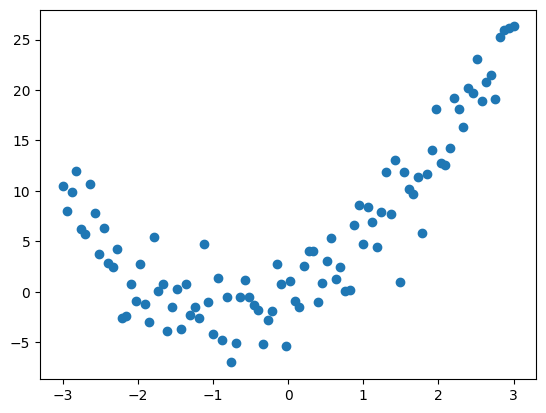

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.scatter(r,s)

In [64]:
linear_model = LinearRegression()
r_reshaped = r.reshape(-1,1)
linear_model.fit(r_reshaped, s)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [65]:
s_pred_linear = linear_model.predict(r_reshaped)

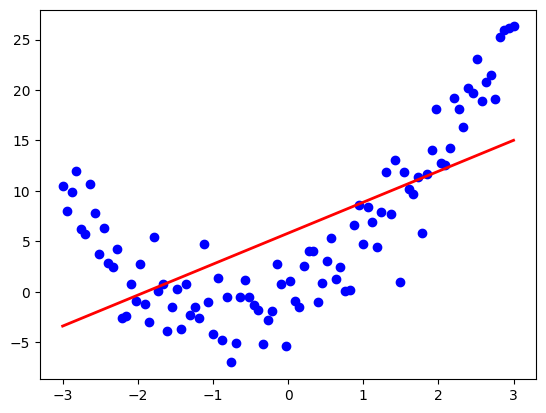

In [66]:
plt.scatter(r,s, color='blue', label='Data')
plt.plot(r,s_pred_linear, color='red', linewidth=2, label='linear_model')

In [67]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
r_poly = poly.fit_transform(r_reshaped)


In [68]:
poly_model = LinearRegression()
poly_model.fit(r_poly,s)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [69]:
s_pred_poly = poly_model.predict(r_poly)


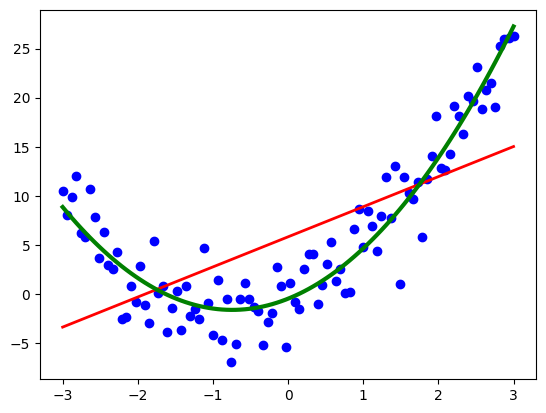

In [70]:
plt.scatter(r, s, color='blue', label='Data')
plt.plot(r, s_pred_linear, color='red', linewidth=2, label='Linear (Degree 1)')
plt.plot(r, s_pred_poly, color='green', linewidth=3, label='Polynomial (Degree 2)')

In [71]:
liner_r2 = r2_score(s,s_pred_linear)
poly_r2 = r2_score(s, s_pred_poly)

print(liner_r2)
print(poly_r2)

0.42418382311830327
0.8924889080126511


In [72]:
from sklearn.metrics import mean_squared_error

r_train, r_test, s_train, s_test  = train_test_split(r_reshaped, s, test_size=0.2, random_state=42)

train_error =[]
test_error = []
for d in range(1,16):
    poly_2 = PolynomialFeatures(degree=d)
    r_train_poly = poly_2.fit_transform(r_train)

    r_test_poly = poly_2.transform(r_test)

    linear_model_2 = LinearRegression()
    linear_model_2.fit(r_train_poly, s_train)

    pred_train = linear_model_2.predict(r_train_poly)
    pred_test = linear_model_2.predict(r_test_poly)

    mse_train = mean_squared_error(s_train,pred_train)
    mse_test = mean_squared_error(s_test, pred_test)

    train_error.append(mse_train)
    test_error.append(mse_test)



    


    

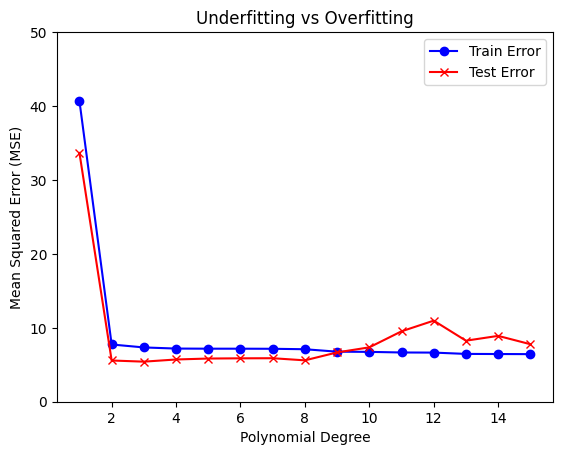

In [73]:
plt.plot(range(1, 16), train_error, label='Train Error', color='blue', marker='o')
plt.plot(range(1, 16), test_error, label='Test Error', color='red', marker='x')

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Underfitting vs Overfitting')
plt.legend()

plt.ylim(0, 50) 

plt.show()

In [74]:
train_data = df_data[['bmi']]
target_data = df_data['target']
x_train, x_test, y_train, y_test = train_test_split(train_data, target_data, test_size=0.2, random_state=42)


In [75]:
my_linear_model = LinearRegression()
my_linear_model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [76]:
linear_pred = my_linear_model.predict(x_test)

In [77]:
linear_r2 = r2_score(y_test, linear_pred)
print(linear_r2)

0.23335039815872138


In [81]:
poly_3 = PolynomialFeatures(degree=2)
x_train_poly = poly_3.fit_transform(x_train)
x_test_poly = poly_3.fit_transform(x_test)

In [82]:
linear_poly = LinearRegression()
linear_poly.fit(x_train_poly,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [83]:
poly_pred = linear_poly.predict(x_test_poly)

In [84]:
poly_pred_r2 = r2_score(y_test, poly_pred)
print(poly_pred_r2)

0.2289715971205668
